In [ ]:
# 2025/03/15
# Ziming Xu, Univeristy of Alberta
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.callbacks import Callback, ModelCheckpoint
import numpy as np
import matplotlib.pyplot as plt
import pickle

## Component1: Proxy Model

In [ ]:
x_data_scaled = pickle.load(open('processed data/proxy_x_scaled.pkl', 'rb'))
y_data_scaled = pickle.load(open('processed data/proxy_y_scaled.pkl', 'rb'))
proxy_x_scaler = pickle.load(open('processed data/proxy_scaler.pkl', 'rb'))
y_scaler = pickle.load(open('processed data/y_scaler.pkl', 'rb'))

/usr/local/lib/python3.11/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RobustScaler from version 1.4.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [ ]:
assert x_data_scaled.shape[0] == y_data_scaled.shape[0], "Batch sizes must match!"

# Create a random permutation of batch indices
np.random.seed(66)
perm = np.random.permutation(x_data_scaled.shape[0])

# Apply the same shuffle to both arrays
x_data_shuffled = x_data_scaled[perm]
y_data_shuffled = y_data_scaled[perm]

# split training and testing set
split_ratio = 0.98
x_train = x_data_shuffled[:int(x_data_shuffled.shape[0]*split_ratio),:,:]
x_test = x_data_shuffled[int(x_data_shuffled.shape[0]*split_ratio):,:,:]
y_train = y_data_shuffled[:int(x_data_shuffled.shape[0]*split_ratio),:,:]
y_test = y_data_shuffled[int(x_data_shuffled.shape[0]*split_ratio):,:,:]

print(f"x_train shape: {x_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"x_test shape: {x_test.shape}")
print(f"y_test shape: {y_test.shape}")

x_train shape: (1725, 36, 19)
y_train shape: (1725, 36, 1)
x_test shape: (36, 36, 19)
y_test shape: (36, 36, 1)


In [ ]:
from tensorflow.keras.layers import Layer
from tensorflow.keras.utils import register_keras_serializable

@register_keras_serializable()
class SelfAttention(Layer):
    def __init__(self, units=128, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.query_dense = keras.layers.Dense(units)
        self.key_dense = keras.layers.Dense(units)
        self.value_dense = keras.layers.Dense(units)
        self.softmax = keras.layers.Softmax(axis=-1)

    def build(self, input_shape):
        # Ensure sub-layers are built with the correct input shape
        self.query_dense.build(input_shape)
        self.key_dense.build(input_shape)
        self.value_dense.build(input_shape)
        super().build(input_shape)

    def call(self, inputs):
        query = self.query_dense(inputs)
        key = self.key_dense(inputs)
        value = self.value_dense(inputs)

        # Transpose key for dot product
        key = tf.transpose(key, perm=[0, 2, 1])
        attention_scores = tf.matmul(query, key) / tf.math.sqrt(tf.cast(self.units, tf.float32))
        attention_weights = self.softmax(attention_scores)
        output = tf.matmul(attention_weights, value)
        return output

def threshold_relu(x):
    v_min = y_train.min()
    return tf.maximum(x, v_min)

In [ ]:
# build a GRU model for regression task
from tensorflow.keras.layers import Dense, Lambda

inputs = keras.layers.Input(shape=(x_data_scaled.shape[1],x_data_scaled.shape[2]))
x = keras.layers.GRU(256, return_sequences=True)(inputs)
x = keras.layers.Dropout(0.2)(x)
x = SelfAttention(units=256)(x)
x = keras.layers.GRU(256, return_sequences=True)(x)
x = keras.layers.Dropout(0.2)(x)
x = keras.layers.Dense(256, activation='relu')(x)
x = keras.layers.Dense(256, activation='relu')(x)
# x = keras.layers.Dense(1)(x)
# x = Lambda(threshold_relu)(x)
x = keras.layers.Dense(1, activation='linear')(x)

model = keras.models.Model(inputs=inputs, outputs=x)
optimizer = keras.optimizers.Adam(learning_rate=0.001)
model.compile(loss='mse', optimizer=optimizer)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 36, 19)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_2 (GRU)                     │ (None, 36, 256)        │       212,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 36, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ self_attention_1                │ (None, 36, 256)        │       197,376 │
│ (SelfAttention)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_3 (GRU)                     │ (None, 36, 256)        │       394,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 36, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 36, 256)        │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 36, 256)        │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 36, 1)          │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 936,705 (3.57 MB)

 Trainable params: 936,705 (3.57 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
class EveryNVerbose(Callback):
    def __init__(self, n=5):
        super().__init__()
        self.n = n

    def on_epoch_end(self, epoch, logs=None):
        if epoch == 0:
            print(f"Epoch {epoch + 1}: loss = {logs['loss']:.5f}, val_loss = {logs.get('val_loss', 0):.5f}")
        elif (epoch + 1) % self.n == 0:
            print(f"Epoch {epoch + 1}: loss = {logs['loss']:.5f}, val_loss = {logs.get('val_loss', 0):.5f}")

# Automatically save the model with the lowest val_loss
checkpoint_cb = ModelCheckpoint(
    filepath='saved models/proxy_best.keras',
    monitor='val_loss',
    save_best_only=True,
    save_weights_only=False,
    verbose=0  # set to 1 to print a message when saving
)

model.fit(x_train, y_train, epochs=500, batch_size=256, validation_split=0.05, verbose=0, callbacks=[EveryNVerbose(n=10), checkpoint_cb])

Epoch 1: loss = 0.00257, val_loss = 0.03481
Epoch 10: loss = 0.00240, val_loss = 0.03463
Epoch 20: loss = 0.00209, val_loss = 0.03435
Epoch 30: loss = 0.00182, val_loss = 0.03391
Epoch 40: loss = 0.00170, val_loss = 0.03590
Epoch 50: loss = 0.00185, val_loss = 0.03420
Epoch 60: loss = 0.00208, val_loss = 0.03402
Epoch 70: loss = 0.00197, val_loss = 0.03418
Epoch 80: loss = 0.00177, val_loss = 0.03409
Epoch 90: loss = 0.00183, val_loss = 0.03467
Epoch 100: loss = 0.00166, val_loss = 0.03474
Epoch 110: loss = 0.00235, val_loss = 0.03602
Epoch 120: loss = 0.00220, val_loss = 0.03334
Epoch 130: loss = 0.00249, val_loss = 0.03530
Epoch 140: loss = 0.00215, val_loss = 0.03578
Epoch 150: loss = 0.00256, val_loss = 0.03478
Epoch 160: loss = 0.00190, val_loss = 0.03683
Epoch 170: loss = 0.00187, val_loss = 0.03323
Epoch 180: loss = 0.00187, val_loss = 0.03321
Epoch 190: loss = 0.00156, val_loss = 0.03494
Epoch 200: loss = 0.00252, val_loss = 0.03595
Epoch 210: loss = 0.00167, val_loss = 0.03485

### Prediction

In [ ]:
proxy = keras.models.load_model('saved models/proxy_best.keras', custom_objects={'SelfAttention': SelfAttention})

In [ ]:
y_pred = proxy.predict(x_test[:,:,:])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


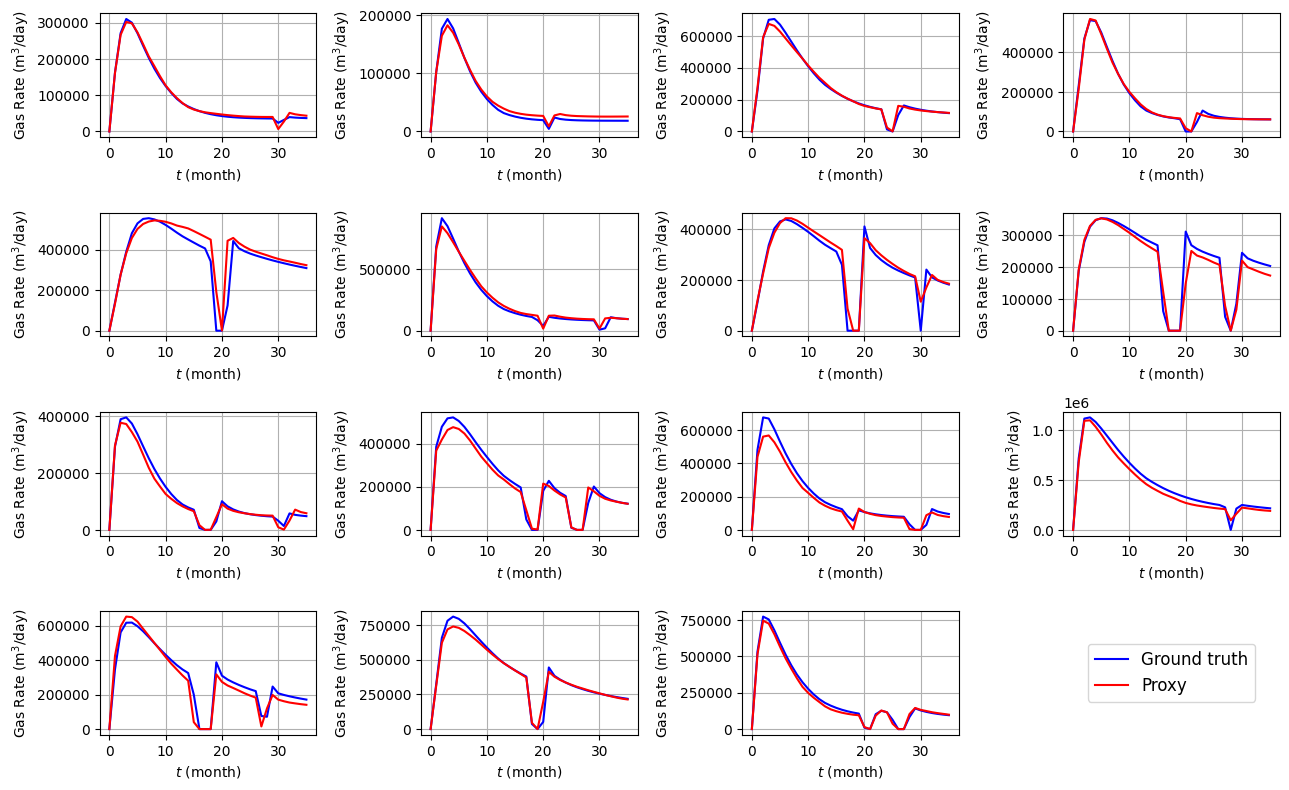

In [ ]:
original_shape = y_pred.shape
y_pred_flat = y_pred.reshape(-1,1)
y_test_flat = y_test.reshape(-1,1)

y_pred_inversed = y_scaler.inverse_transform(y_pred_flat).reshape(original_shape)
y_pred_inversed[y_pred_inversed<0] = 0
y_test_inversed = y_scaler.inverse_transform(y_test_flat).reshape(original_shape)

fig, ax = plt.subplots(4, 4, figsize=(13, 8))
ax = ax.flatten()

plot_idxs = [1, 3,6,8,10,11,13,15,16,17,18,20,23,26,27]
for i in range(15):  # Only plot 15 subplots (0 to 14)
    plot_idx = plot_idxs[i]
    ax[i].plot(y_test_inversed[plot_idx, :, 0], label='Ground truth', color='blue')
    ax[i].plot(y_pred_inversed[plot_idx, :, 0], label='Proxy', color='red')
    ax[i].set_ylabel('Gas Rate (m$^3$/day)', fontsize=10)
    ax[i].set_xlabel('$t$ (month)', fontsize=10)
    ax[i].grid(True)

# Use the 16th subplot for a legend only
ax[15].axis('off')
line1, = ax[15].plot([], [], label='Ground truth', color='blue')
line2, = ax[15].plot([], [], label='Proxy', color='red')
ax[15].legend(handles=[line1, line2], loc='center', fontsize=12)

plt.tight_layout()
plt.show()

### Config the prehistory matching

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler
import json

def sample_config_run():
    # === Define well config ===
    config = {
    "cases": [
        {"stage_range": [12, 12], "ave_frac_spacing_range": [202, 202], "thickness_range": [46, 46], "depth_range": [1909, 1909], "special_code": "Well01"},
        {"stage_range": [16, 16], "ave_frac_spacing_range": [111, 111], "thickness_range": [83, 83], "depth_range": [2357, 2357], "special_code": "Well02"},
        {"stage_range": [15, 15], "ave_frac_spacing_range": [92, 92], "thickness_range": [65, 65], "depth_range": [2708, 2708], "special_code": "Well03"},
        {"stage_range": [19, 19], "ave_frac_spacing_range": [93, 93], "thickness_range": [54, 54], "depth_range": [2047, 2047], "special_code": "Well04"},
        {"stage_range": [37, 37], "ave_frac_spacing_range": [74, 74], "thickness_range": [77, 77], "depth_range": [2715, 2715], "special_code": "Well05"},
        {"stage_range": [11, 11], "ave_frac_spacing_range": [141, 141], "thickness_range": [58, 58], "depth_range": [2665, 2665], "special_code": "Well06"}
    ]
}

    # === Sampling range for variables ===
    param_ranges = {
        'pressure_diff': (4000, 9000),
        'PERM *MATRIX': (0.00001, 0.0001),
        'POR *MATRIX': (0.005, 0.08),
        'SW *MATRIX': (0.1, 0.4),
        'POR *FRACTURE': (0.00001, 0.001),
        'PERM *FRACTURE': (0.01, 0.1),
        'frac_length': (50, 120),
        'frac_height': (30, 60),
        'POR **FRACTURE': (0.01, 0.1),
        'PERMI **FRACTURE': (1, 5),
        'SW **FRACTURE': (0.6, 0.75),
        'Ew': (2, 8),
        'Eg': (2, 8)
    }

    # === Generate random samples for unspecified variables ===
    samples = pd.DataFrame({
        key: np.random.uniform(low, high, size=6) for key, (low, high) in param_ranges.items()
    })

    # === Assign fixed config values ===
    for i, case in enumerate(config["cases"]):
        samples.loc[i, 'DEPTH TVD'] = case['depth_range'][0]
        samples.loc[i, 'stage'] = case['stage_range'][0]
        samples.loc[i, 'ave_frac_spacing'] = case['ave_frac_spacing_range'][0]
        samples.loc[i, 'thickness'] = case['thickness_range'][0]

    # === Compute derived variables ===
    samples["PRES *MATRIX"] = samples["DEPTH TVD"] * 12.85
    samples["PRES *FRACTURE"] = samples["PRES *MATRIX"]
    samples["SW *FRACTURE"] = samples["SW *MATRIX"] + 0.1
    samples["PERM *FRACTURE"] = samples["PERM *FRACTURE"]  # Placeholder or logic override

    # === Arrange columns in expected proxy model order ===
    ordered_columns = [
        'pressure_diff', 'DEPTH TVD', 'PERM *MATRIX', 'POR *MATRIX', 'SW *MATRIX',
        'PRES *MATRIX', 'PERM *FRACTURE', 'POR *FRACTURE', 'SW *FRACTURE', 'stage',
        'ave_frac_spacing', 'thickness', 'frac_length', 'frac_height',
        'POR **FRACTURE', 'PERMI **FRACTURE', 'SW **FRACTURE', 'Ew', 'Eg'
    ]

    samples = samples[ordered_columns]

    # # === Scale the inputs using your pretrained proxy_scaler ===
    n_samples = samples.shape[0]
    # Step 1: Repeat current (n, 21) vector to (n, 36, 21)
    repeated = np.repeat(samples.values[:, np.newaxis, :], 36, axis=1)  # (n, 36, 21)

    # # Step 2: Add a column for 'total producing month' from 1 to 36
    producing_month = np.arange(1, 37).reshape(1, 36, 1)
    producing_month = np.repeat(producing_month, n_samples, axis=0)
    proxy_input_data = np.concatenate([repeated, producing_month], axis=-1)  # (n, 36, 22)

    # # Step 4: Create DataFrame with correct column names
    proxy_input_columns = ordered_columns + ['total producing month']
    flat_array = proxy_input_data.reshape(-1, len(proxy_input_columns))
    samples_df = pd.DataFrame(flat_array, columns=proxy_input_columns)

    # # Step 4: Perform scaling on the DataFrame
    x_config_scaled_df = proxy_x_scaler.transform(samples_df)  # (n*36, 20)

    # # Step 5: Add shut-in signal after scaling
    shut_in_signal = np.zeros((n_samples, 36, 1))
    shut_in_signal[:, 0, 0] = 1

    x_df_scaled = pd.DataFrame(x_config_scaled_df, columns=samples_df.columns)
    x_df_scaled['shut-in signal'] = shut_in_signal.reshape(-1)

    x_config_scaled = np.array(x_df_scaled)
    x_config_scaled = x_config_scaled.reshape(6, 36, 21)
    # print(f"Scaled input shape: {x_config_scaled.shape}")

    return x_config_scaled

In [ ]:
def read_well_data(file_path):
    data = []
    current_well_id = None

    with open(file_path, 'r') as file:
        for line in file:
            line = line.strip()
            if not line:
                continue  # skip empty lines

            if line.startswith("'") and line.endswith("'"):
                # new well ID line
                current_well_id = line.strip("'")
            else:
                # date-volume-gas line
                parts = line.split()
                if len(parts) == 3:
                    date, volume, gas = parts
                    data.append({
                        "Well ID": current_well_id,
                        "Date": pd.to_datetime(date),
                        "GAS": float(volume),
                        "oil": float(gas)
                    })

    return pd.DataFrame(data)

file_path = 'processed data0/prod_config.txt'
config_prod = read_well_data(file_path)

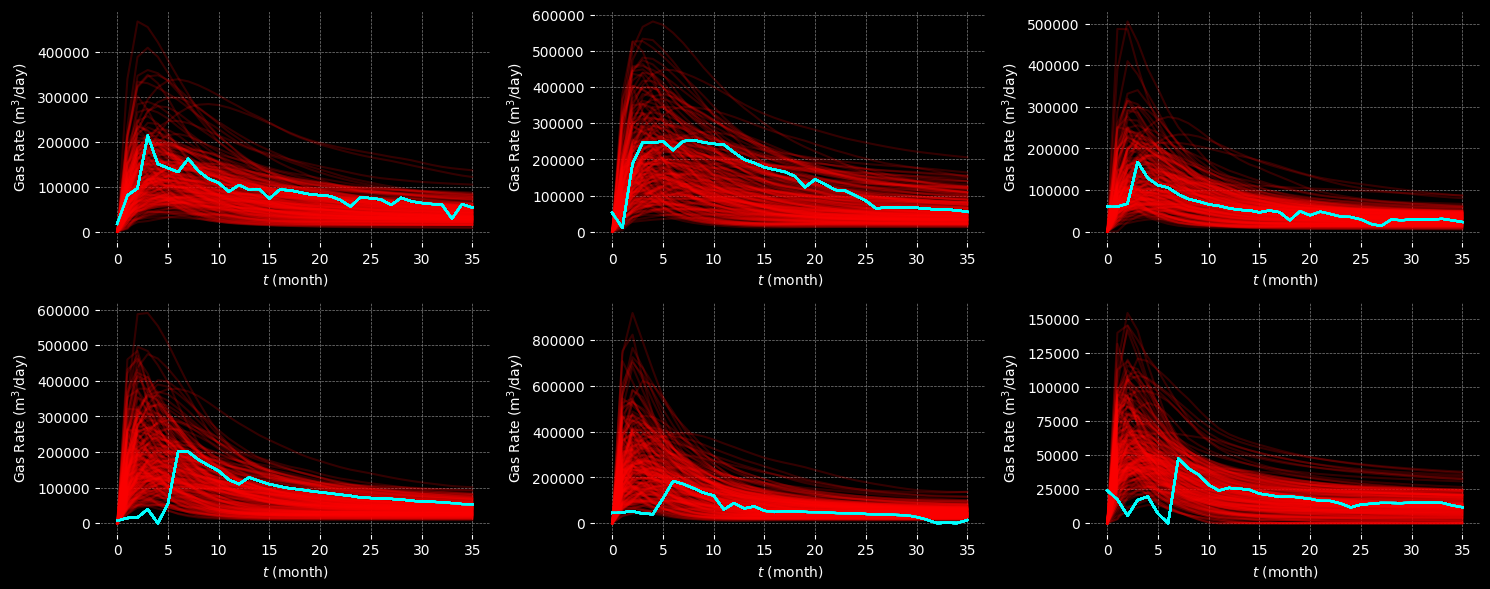

In [ ]:
y_pred_inversed_store = []
n_sampling = 200

for i in range(n_sampling):
    x_config_scaled = sample_config_run()
    y_pred = proxy.predict(x_config_scaled, verbose=0)
    original_shape = y_pred.shape
    y_pred_flat = y_pred.reshape(-1, 1)
    y_pred_inversed = y_scaler.inverse_transform(y_pred_flat).reshape(original_shape)
    y_pred_inversed_store.append(y_pred_inversed)

fig, ax = plt.subplots(2, 3, figsize=(15, 6))
ax = ax.flatten()

for i in range(6):
    plot_idx = i
    plot_x_range = list(range(36))

    for j in range(n_sampling):
        ax[i].plot(plot_x_range, y_pred_inversed_store[j][plot_idx, :, 0], label='Proxy', color='red', alpha=0.2)
        ax[i].plot(plot_x_range, config_prod['GAS'][plot_idx*36:(plot_idx+1)*36], label='Ground truth', color='cyan')

    ax[i].set_ylabel('Gas Rate (m$^3$/day)', fontsize=10, color='white')
    ax[i].set_xlabel('$t$ (month)', fontsize=10, color='white')
    ax[i].tick_params(colors='white')  # change tick colors
    ax[i].grid(True, color='gray', linestyle='--', linewidth=0.5)
    ax[i].set_facecolor('black')  # explicitly set axes background

    # if i == 0:
    #     ax[i].legend(loc='upper right', fontsize=8)

fig.patch.set_facecolor('black')  # figure background
plt.tight_layout()
plt.show()

## Component2: VAE

In [ ]:
vae_data_scaled = pickle.load(open('processed data/vae_x_scaled.pkl', 'rb'))
vae_scaler = pickle.load(open('processed data/vae_scaler.pkl', 'rb'))

In [5]:
np.random.seed(66)
perm = np.random.permutation(vae_data_scaled.shape[0])

vae_data_scaled = vae_data_scaled[perm]

vae_data_train = vae_data_scaled[:int(vae_data_scaled.shape[0]*0.98)]
vae_data_test = vae_data_scaled[int(vae_data_scaled.shape[0]*0.98):]
print(f"vae_data_train shape: {vae_data_train.shape}")
print(f"vae_data_test shape: {vae_data_test.shape}")

vae_data_train shape: (6625, 13)
vae_data_test shape: (136, 13)


In [6]:
class Sampling(keras.layers.Layer):
    """Uses (z_mean, z_log_var) to sample z, the vector encoding a digit."""

    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

In [7]:
latent_dim = 100

# VAE_Encoder
encoder_input = keras.layers.Input(shape=(vae_data_scaled.shape[1],))

VAE_en1 = keras.layers.Dense(128, activation = 'relu')(encoder_input)
VAE_en1 = keras.layers.Dropout(0.2)(VAE_en1)
VAE_en2 = keras.layers.Dense(128, activation = 'relu')(VAE_en1)
VAE_en2 = keras.layers.Dropout(0.2)(VAE_en2)

x = keras.layers.Flatten()(VAE_en2)
z_mean = keras.layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = keras.layers.Dense(latent_dim, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])

# Define the model
VAE_encoder = keras.Model([encoder_input], [z_mean, z_log_var, z], name="VAE_encoder")
VAE_encoder.summary()

Model: "VAE_encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 13)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │      1,792 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     16,512 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 128)       │          0 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 100)       │     12,900 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 100)       │     12,900 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 100)       │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 44,104 (172.28 KB)

 Trainable params: 44,104 (172.28 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# VAE_Decoder
decoder_input = keras.Input(shape=(latent_dim,),name='latent_input')

VAE_de1 = keras.layers.Dense(128, activation = 'relu')(decoder_input)
VAE_de1 = keras.layers.Dropout(0.2)(VAE_de1)
VAE_de2 = keras.layers.Dense(128, activation = 'relu')(VAE_de1)
VAE_de2 = keras.layers.Dropout(0.2)(VAE_de2)
VAE_de_dense1 = keras.layers.Dense(128, activation='tanh')(VAE_de2)
VAE_de_output = keras.layers.Dense(vae_data_scaled.shape[1], activation = 'linear')(VAE_de_dense1)

VAE_decoder = keras.Model([decoder_input], VAE_de_output, name="VAE_decoder")
VAE_decoder.summary()

Model: "VAE_decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ latent_input (InputLayer)            │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_13 (Dense)                     │ (None, 128)                 │          12,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_10 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_11 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 13)                  │           1,677 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 47,629 (186.05 KB)

 Trainable params: 47,629 (186.05 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#%% Define VAE
class Build_VAE(keras.Model):
    def __init__(self, encoder, decoder, clip_min= None, clip_max = None, **kwargs):
        super().__init__(**kwargs)
        self.gamma = 5000 # add weight to the reonstruction loss
        self.encoder = VAE_encoder
        self.decoder = VAE_decoder
        self.encoder_loss_tracker = keras.metrics.Mean(name="encoder_loss")
        self.recons_loss_tracker = keras.metrics.Mean(name="recons_loss")

        self.optimizer = tf.keras.optimizers.Adam(learning_rate = 0.0001)

        if clip_min is not None and clip_max is not None:
            self.clip_min = clip_min
            self.clip_max = clip_max

    @property
    def metrics(self):
        return [
            self.encoder_loss_tracker,
            self.recons_loss_tracker]

    def clip_by_value(self, tensor):
        return tf.clip_by_value(tensor, self.clip_min, self.clip_max)

    def train_step(self, data):
        en_features = data[0][0]

        # VAE
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder([en_features])

            kl_loss = -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
            kl_loss = tf.reduce_mean(tf.reduce_sum(kl_loss, axis=1))

            reconstruction = self.decoder([z])
            reconstruction_loss = tf.reduce_mean(tf.keras.losses.MeanSquaredError()(en_features, reconstruction))

            # # --------------------------
            # # Add penalty for out-of-bounds values
            # # --------------------------
            # if hasattr(self, "clip_min") and hasattr(self, "clip_max"):
            #     # Compute penalties for each bound violation
            #     over_max = tf.maximum(reconstruction - self.clip_max, 0.0)
            #     under_min = tf.maximum(self.clip_min - reconstruction, 0.0)
            #     penalty = tf.reduce_mean(tf.square(over_max) + tf.square(under_min))
            # else:
            #     penalty = 0.0  # no bounds specified

            # # Total loss
            # total_loss = kl_loss + self.gamma * reconstruction_loss + self.gamma * penalty *10  # you can weight penalty separately
            total_loss = kl_loss + self.gamma * reconstruction_loss

        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.encoder_loss_tracker.update_state(kl_loss)
        self.recons_loss_tracker.update_state(reconstruction_loss)

        return {
            "kl": self.encoder_loss_tracker.result(),
            "recons": self.recons_loss_tracker.result()
        }

In [ ]:
vae = Build_VAE(VAE_encoder, VAE_decoder, vae_data_train.min(0), vae_data_train.max(0))
vae.compile(tf.keras.optimizers.Adam())

In [ ]:
class EveryNVerbose(Callback):
    def __init__(self, n=5):
        super().__init__()
        self.n = n

    def on_epoch_end(self, epoch, logs=None):
        if epoch == 0:
            print(f"Epoch {epoch + 1}: KL loss = {logs['kl']:.9f}, Reconstruction loss = {logs['recons']:.5f}")
        elif (epoch + 1) % self.n == 0:
            print(f"Epoch {epoch + 1}: KL loss = {logs['kl']:.9f}, Reconstruction loss = {logs['recons']:.5f}")


# Automatically save the encoder and the decoder
class SaveEncoderDecoder(Callback):
    def __init__(self, encoder_path, decoder_path, monitor='recons', save_best_only=True):
        super().__init__()
        self.encoder_path = encoder_path
        self.decoder_path = decoder_path
        self.monitor = monitor
        self.save_best_only = save_best_only
        self.best = float('inf')  # initialize as very bad (infinite loss)

    def on_epoch_end(self, epoch, logs=None):
        current = logs.get(self.monitor)
        if current is None:
            print(f"Warning: Metric '{self.monitor}' not found in logs.")
            return

        # Save if either not save_best_only or new best
        if not self.save_best_only or current < self.best:
            self.best = current
            print(f"Saving encoder and decoder at epoch {epoch + 1} with {self.monitor}: {current:.6f}")
            self.model.encoder.save(self.encoder_path)
            self.model.decoder.save(self.decoder_path)

save_cb = SaveEncoderDecoder(
    encoder_path='saved models/vae_encoder_best2.keras',
    decoder_path='saved models/vae_decoder_best2.keras',
    monitor='recons',
    save_best_only=True
)

vae.fit([vae_data_train],
        epochs=2000, batch_size=1024, verbose = 0, callbacks= [EveryNVerbose(n=50), save_cb])

Epoch 1: KL loss = 1.167039752, Reconstruction loss = 0.49674
Saving encoder and decoder at epoch 1 with recons: 0.496736
Saving encoder and decoder at epoch 2 with recons: 0.391093
Saving encoder and decoder at epoch 3 with recons: 0.358223
Saving encoder and decoder at epoch 4 with recons: 0.337148
Saving encoder and decoder at epoch 5 with recons: 0.316912
Saving encoder and decoder at epoch 6 with recons: 0.287152
Saving encoder and decoder at epoch 7 with recons: 0.239406
Saving encoder and decoder at epoch 8 with recons: 0.181664
Saving encoder and decoder at epoch 9 with recons: 0.118585
Saving encoder and decoder at epoch 10 with recons: 0.072800
Saving encoder and decoder at epoch 11 with recons: 0.046417
Saving encoder and decoder at epoch 12 with recons: 0.031963
Saving encoder and decoder at epoch 13 with recons: 0.026824
Saving encoder and decoder at epoch 14 with recons: 0.023260
Saving encoder and decoder at epoch 15 with recons: 0.021316
Saving encoder and decoder at ep

In [ ]:
custom_objects = {'Sampling': Sampling}
encoder_model = tf.keras.models.load_model('saved models/vae_encoder_best2.keras',custom_objects=custom_objects)
decoder_model = tf.keras.models.load_model('saved models/vae_decoder_best2.keras')

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


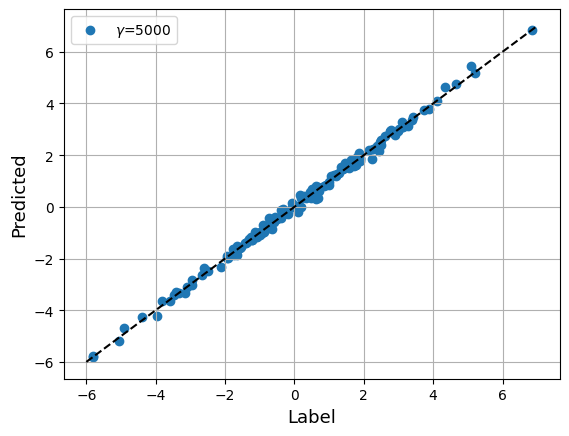

In [10]:
en_pred = encoder_model.predict([vae_data_test])
de_pred = decoder_model.predict([en_pred[2]])

x_test_sum = np.sum(vae_data_test,axis=1)
de_pred_sum = np.sum(de_pred,axis=1)
plt.scatter(x_test_sum,de_pred_sum,label="$γ$=5000")
plt.plot([-6,7],[-6,7],'k--')
plt.xlabel('Label',fontsize = 13)
plt.ylabel('Predicted',fontsize = 13)
plt.legend()
plt.grid()

## Component3: AssimNet

In [ ]:
assim_x1_scaled = pickle.load(open('processed data/assim_x1_scaled.pkl', 'rb'))
assim_x2_scaled  = pickle.load(open('processed data/assim_x2_scaled.pkl', 'rb'))
assim_y_scaled  = pickle.load(open('processed data/assim_y_scaled.pkl', 'rb'))
assim_y_org_scaled  = pickle.load(open('processed data/assim_y_org_scaled.pkl', 'rb'))

# ✅ Sanity check
assert assim_x1_scaled.shape[0] == assim_x2_scaled.shape[0] == assim_y_scaled.shape[0], "Sample size mismatch!"

# Shuffle consistently
np.random.seed(66)
perm = np.random.permutation(assim_x1_scaled.shape[0])

assim_x1_scaled = assim_x1_scaled[perm]
assim_x2_scaled = assim_x2_scaled[perm]
assim_y_scaled  = assim_y_scaled[perm]
assim_y_org_scaled  = assim_y_org_scaled[perm]

# ✅ Load training and testing data
assim_x1_scaled_train = pickle.load(open('processed data05a/field data/assim_x1_scaled_train.pkl', 'rb'))
assim_x2_scaled_train = pickle.load(open('processed data05a/field data/assim_x2_scaled_train.pkl', 'rb'))
assim_y_scaled_train  = pickle.load(open('processed data05a/field data/assim_y_scaled_train.pkl', 'rb'))
assim_y_org_scaled_train = pickle.load(open('processed data05a/field data/assim_y_org_scaled_train.pkl', 'rb'))

assim_x1_scaled_test = pickle.load(open('processed data05a/field data/assim_x1_scaled_test.pkl', 'rb'))
assim_x2_scaled_test = pickle.load(open('processed data05a/field data/assim_x2_scaled_test.pkl', 'rb'))
assim_y_scaled_test  = pickle.load(open('processed data05a/field data/assim_y_scaled_test.pkl', 'rb'))
assim_y_org_scaled_test = pickle.load(open('processed data05a/field data/assim_y_org_scaled_test.pkl', 'rb'))

# ✅ Print final shapes
print(f"assim_x1_scaled_train shape: {assim_x1_scaled_train.shape}")
print(f"assim_x2_scaled_train shape: {assim_x2_scaled_train.shape}")
print(f"assim_y_scaled_train  shape: {assim_y_scaled_train.shape}")
print(f"assim_x1_scaled_test  shape: {assim_x1_scaled_test.shape}")
print(f"assim_x2_scaled_test  shape: {assim_x2_scaled_test.shape}")
print(f"assim_y_scaled_test   shape: {assim_y_scaled_test.shape}")
print(f"assim_y_org_scaled_train  shape: {assim_y_org_scaled_train.shape}")
print(f"assim_y_org_scaled_test   shape: {assim_y_org_scaled_test.shape}")
print("====")
# print(f"assim_x2_train shape: {assim_x2_train.shape}")
# print(f"assim_x2_test  shape: {assim_x2_test.shape}")

assim_x1_scaled_train shape: (1427, 27)
assim_x2_scaled_train shape: (1427, 36, 6)
assim_y_scaled_train  shape: (1427, 36, 1)
assim_x1_scaled_test  shape: (59, 27)
assim_x2_scaled_test  shape: (59, 36, 6)
assim_y_scaled_test   shape: (59, 36, 1)
assim_y_org_scaled_train  shape: (1427, 36, 1)
assim_y_org_scaled_test   shape: (59, 36, 1)
====


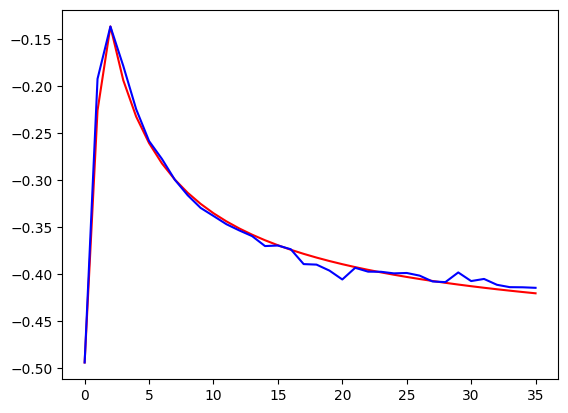

In [ ]:
for i in range(20,21):
    plt.plot(assim_y_scaled_train[i+20,:,:], 'r')
    plt.plot(assim_y_org_scaled_train[i+20,:,:], 'b')

In [ ]:
## Define the Encoder
latent_dim = 100
encoder_input = keras.layers.Input(shape=(assim_x1_scaled.shape[1],))

Assim_en1 = keras.layers.Dense(128, activation = 'relu')(encoder_input)
Assim_en1 = keras.layers.Dropout(0.2)(Assim_en1)
Assim_en2 = keras.layers.Dense(128, activation = 'relu')(Assim_en1)
Assim_en2 = keras.layers.Dropout(0.2)(Assim_en2)

x = keras.layers.Flatten()(Assim_en2)
z_mean = keras.layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = keras.layers.Dense(latent_dim, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])

# Define the model
Assim_encoder = keras.Model([encoder_input], [z_mean, z_log_var, z], name="Assim_encoder")
Assim_encoder.summary()

Model: "Assim_encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5             │ (None, 27)             │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_17 (Dense)          │ (None, 128)            │          3,584 │ input_layer_5[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_12 (Dropout)      │ (None, 128)            │              0 │ dense_17[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_18 (Dense)          │ (None, 128)            │         16,512 │ dropout_12[0][0]       │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_13 (Dropout)      │ (None, 128)            │              0 │ dense_18[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ flatten_5 (Flatten)       │ (None, 128)            │              0 │ dropout_13[0][0]       │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ z_mean (Dense)            │ (None, 100)            │         12,900 │ flatten_5[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ z_log_var (Dense)         │ (None, 100)            │         12,900 │ flatten_5[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ sampling_5 (Sampling)     │ (None, 100)            │              0 │ z_mean[0][0],          │
│                           │                        │                │ z_log_var[0][0]        │
└───────────────────────────┴────────────────────────┴────────────────┴────────────────────────┘

 Total params: 45,896 (179.28 KB)

 Trainable params: 45,896 (179.28 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
def assemble_simu_in(simu_in_recons, assim_x2):
    """
    Assemble simulation input by merging the decoder output (uncertain_cols)
    and field-known features (determined_cols + extra_cols), and reordering to match final_order.
    """
    # Input shape assertions:
    tf.debugging.assert_equal(tf.shape(simu_in_recons)[-1], 13, message="simu_in_recons must have 13 features")
    tf.debugging.assert_equal(tf.shape(assim_x2)[-1], 6, message="assim_x2 must have 6 features")

    batch_size = tf.shape(simu_in_recons)[0]

    # Repeat the decoder output over 36 timesteps
    simu_in_repeated = tf.repeat(tf.expand_dims(simu_in_recons, axis=1), repeats=36, axis=1)  # [batch_size, 36, 15]

    # Split assim_x2: [batch_size, 36, 6] → determined (4), extra (2)
    assim_x2_determined = assim_x2[:, :, :4]  # ['DEPTH TVD', 'stage', 'ave_frac_spacing', 'thickness']
    assim_x2_extra = assim_x2[:, :, 4:]       # ['total producing month', 'shut-in signal']

    # Build the mapping: column name → tensor
    feature_map = {}

    # uncertain_cols in the same order as in final_order
    uncertain_cols = ['pressure_diff','PERM *MATRIX', 'POR *MATRIX', 'SW *MATRIX', 'PERM *FRACTURE', 'POR *FRACTURE',
                      'frac_length', 'frac_height', 'POR **FRACTURE', 'PERMI **FRACTURE','SW **FRACTURE', 'Ew', 'Eg']
    for i, col in enumerate(uncertain_cols):
        feature_map[col] = simu_in_repeated[:, :, i]

    determined_cols = ['DEPTH TVD', 'stage', 'ave_frac_spacing', 'thickness']
    for i, col in enumerate(determined_cols):
        feature_map[col] = assim_x2_determined[:, :, i]

    extra_cols = ['total producing month', 'shut-in signal']
    for i, col in enumerate(extra_cols):
        feature_map[col] = assim_x2_extra[:, :, i]

    # Reconstruct input in the correct final order
    final_order = ['pressure_diff', 'DEPTH TVD', 'PERM *MATRIX', 'POR *MATRIX',
          'SW *MATRIX', 'PERM *FRACTURE', 'POR *FRACTURE', 'stage', 'ave_frac_spacing', 'thickness', 'frac_length',
          'frac_height', 'POR **FRACTURE', 'PERMI **FRACTURE', 'SW **FRACTURE',
          'Ew', 'Eg', 'total producing month', 'shut-in signal']

    reordered_features = [tf.expand_dims(feature_map[col], axis=-1) for col in final_order]
    simu_in_concat = tf.concat(reordered_features, axis=-1)  # [batch_size, 36, 21]

    return simu_in_concat

In [ ]:
def kl_divergence_between_gaussians(mu_q, logvar_q, mu_p, logvar_p):
    """KL divergence between two multivariate diagonal Gaussians"""
    var_q = tf.exp(logvar_q)
    var_p = tf.exp(logvar_p)

    kl = 0.5 * (
        tf.reduce_sum(logvar_p - logvar_q, axis=1)  # log |Σ_p| / |Σ_q|
        - tf.cast(tf.shape(mu_q)[1], tf.float32)    # -k
        + tf.reduce_sum(var_q / var_p, axis=1)       # Tr(Σ_p^-1 Σ_q)
        + tf.reduce_sum((mu_p - mu_q)**2 / var_p, axis=1)  # diff^T Σ_p^-1 diff
    )
    return tf.reduce_mean(kl)

class Build_AssimNet(keras.Model):
    def __init__(self, encoder, vae_encoder, decoder, proxy, clip_min, clip_max, **kwargs):
        super().__init__(**kwargs)
        self.lam = 0.001
        self.assim_encoder = encoder
        self.vae_encoder = vae_encoder
        self.decoder = decoder
        self.proxy = proxy
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")
        self.recons_loss_tracker = keras.metrics.Mean(name="recons_loss")
        self.assim_loss_tracker = keras.metrics.Mean(name="assim_loss")
        self.val_loss_tracker = keras.metrics.Mean(name="vaL_loss")
        self.optimizer = tf.keras.optimizers.Adam(learning_rate = 0.0001)
        # clip constraints
        self.clip_min = tf.convert_to_tensor(clip_min, dtype=tf.float32)
        self.clip_max = tf.convert_to_tensor(clip_max, dtype=tf.float32)

        # Set decoder and proxy as untrainable
        self.vae_encoder.trainable = False
        self.decoder.trainable = False
        self.proxy.trainable = False

    @property
    def metrics(self):
        return [self.kl_loss_tracker,
                self.recons_loss_tracker,
                self.assim_loss_tracker,
                self.val_loss_tracker]

    def clip_by_value(self, tensor):
        return tf.clip_by_value(tensor, self.clip_min, self.clip_max)

    def train_step(self, data):
        assim_x1 = data[0][0]
        assim_x2 = data[0][1]
        assim_target = data[0][2]


        # VAE
        with tf.GradientTape() as tape:
            mu_q, logvar_q, z = self.assim_encoder([assim_x1])

            # KL loss
            recons4vae_encoder = self.decoder(z)
            mu_p, logvar_p, _ = self.vae_encoder(recons4vae_encoder)
            kl_loss = kl_divergence_between_gaussians(mu_q, logvar_q, mu_p, logvar_p)

            # Reconstruction loss
            simu_in_recons = self.decoder(z)
            # simu_in_clip = self.clip_by_value(simu_in_recons)

            simu_in_concate = assemble_simu_in(simu_in_recons,assim_x2)
            proxy_out = self.proxy(simu_in_concate)
            recons_loss = tf.keras.losses.MeanSquaredError()(proxy_out, assim_target)

            # Total loss
            assim_loss = recons_loss + kl_loss * self.lam
            # assim_loss = recons_loss


        grads = tape.gradient(assim_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.kl_loss_tracker.update_state(kl_loss)
        self.recons_loss_tracker.update_state(recons_loss)
        self.assim_loss_tracker.update_state(assim_loss)

        return {"kl_loss": self.kl_loss_tracker.result(),
                "recons_loss": self.recons_loss_tracker.result(),
                "assim_loss": self.assim_loss_tracker.result()}

    def test_step(self, data):
        assim_x1 = data[0][0]
        assim_x2 = data[0][1]
        assim_target = data[0][2]

        _, _, z = self.assim_encoder([assim_x1])

        simu_in_recons = self.decoder(z)
        simu_in_concate = assemble_simu_in(simu_in_recons,assim_x2)
        proxy_out = self.proxy(simu_in_concate)
        recons_loss = tf.keras.losses.MeanSquaredError()(proxy_out, assim_target)

        self.val_loss_tracker.update_state(recons_loss)

        return {
            "val_loss": self.val_loss_tracker.result(),
        }


In [ ]:
clip_min = vae_data_scaled.min(axis=0)
clip_max = vae_data_scaled.max(axis=0)
AssimNet = Build_AssimNet(Assim_encoder, encoder_model, decoder_model, proxy, clip_min, clip_max)
AssimNet.compile(tf.keras.optimizers.Adam())

In [ ]:
class EveryNVerbose(Callback):
    def __init__(self, n=5):
        super().__init__()
        self.n = n

    def on_epoch_end(self, epoch, logs=None):
        if epoch == 0:
            print(f"Epoch {epoch + 1}: KL loss = {logs['kl_loss']:.9f}, Recons loss = {logs['recons_loss']:.5f}, Assim loss = {logs['assim_loss']:.5f}, val loss = {logs['val_val_loss']:.5f}")
        elif (epoch + 1) % self.n == 0:
            print(f"Epoch {epoch + 1}: KL loss = {logs['kl_loss']:.9f}, Recons loss = {logs['recons_loss']:.5f}, Assim loss = {logs['assim_loss']:.5f}, val loss = {logs['val_val_loss']:.5f}")

# Automatically save the model with the lowest val_loss
class SaveEncoderDecoder(Callback):
    def __init__(self, encoder_path, monitor='recons_loss', save_best_only=True):
        super().__init__()
        self.encoder_path = encoder_path
        self.monitor = monitor
        self.save_best_only = save_best_only
        self.best = float('inf')  # initialize as very bad (infinite loss)

    def on_epoch_end(self, epoch, logs=None):
        current = logs.get(self.monitor)
        if current is None:
            print(f"Warning: Metric '{self.monitor}' not found in logs.")
            return

        # Save if either not save_best_only or new best
        if not self.save_best_only or current < self.best:
            self.best = current
            print(f"Saving assimnet encoder at epoch {epoch + 1} with {self.monitor}: {current:.6f}")
            self.model.assim_encoder.save(self.encoder_path)

save_cb = SaveEncoderDecoder(
    encoder_path='/content/drive/MyDrive/Colab Notebooks/24_0805_AssimNet/Montney field application/saved models05a/assim_encoder_best.keras',
    monitor='val_val_loss',
    save_best_only=True
)

# history = AssimNet.fit([assim_x1_scaled_train,assim_x2_scaled_train,assim_y_scaled_train],epochs=5000, batch_size=128, verbose = 0, validation_split = 0.1, callbacks=[EveryNVerbose(n=10), save_cb])
history = AssimNet.fit([assim_x1_scaled_train,assim_x2_scaled_train,assim_y_scaled_train],epochs=1000, batch_size=256, verbose = 0, validation_split = 0.1, callbacks=[EveryNVerbose(n=10), save_cb])

Epoch 1: KL loss = 2818.553955078, Recons loss = 0.11746, Assim loss = 2.93602, val loss = 0.11246
Saving assimnet encoder at epoch 1 with val_val_loss: 0.112457
Saving assimnet encoder at epoch 2 with val_val_loss: 0.090281
Saving assimnet encoder at epoch 3 with val_val_loss: 0.071644
Saving assimnet encoder at epoch 6 with val_val_loss: 0.070347
Saving assimnet encoder at epoch 7 with val_val_loss: 0.065395
Saving assimnet encoder at epoch 8 with val_val_loss: 0.061036
Saving assimnet encoder at epoch 9 with val_val_loss: 0.060516
Epoch 10: KL loss = 41.878009796, Recons loss = 0.05800, Assim loss = 0.09988, val loss = 0.06307
Saving assimnet encoder at epoch 11 with val_val_loss: 0.058969
Saving assimnet encoder at epoch 12 with val_val_loss: 0.056673
Saving assimnet encoder at epoch 14 with val_val_loss: 0.054502
Saving assimnet encoder at epoch 15 with val_val_loss: 0.052967
Saving assimnet encoder at epoch 16 with val_val_loss: 0.052674
Saving assimnet encoder at epoch 17 with v

Text(0, 0.5, 'KL Loss')

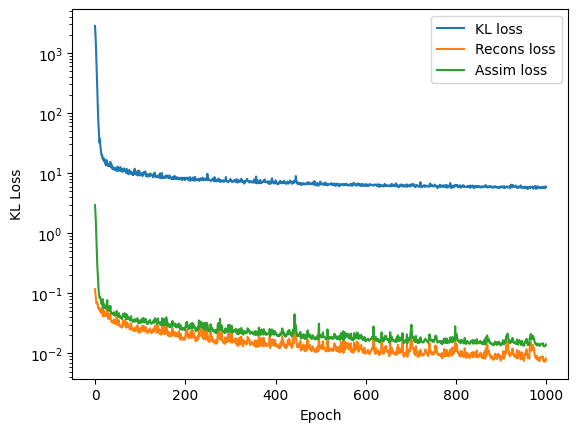

In [ ]:
import pickle
pickle.dump(history.history, open('history.pkl', 'wb'))
history = pickle.load(open('history.pkl', 'rb'))
plt.plot(history['kl_loss'], label='KL loss')
plt.plot(history['recons_loss'], label='Recons loss')
plt.plot(history['assim_loss'], label='Assim loss')
plt.legend()
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('KL Loss')

In [ ]:
AssimNet_encoder = tf.keras.models.load_model('saved models/assim_encoder_best.keras',custom_objects=custom_objects)

## GRU-ATT Model comparison

In [ ]:
## Define the Encoder
encoder_input1 = keras.layers.Input(shape=(assim_x1_scaled.shape[1],))
encoder_input2 = keras.layers.Input(shape=(assim_x2_scaled.shape[1], assim_x2_scaled.shape[2]))

x = keras.layers.RepeatVector(36)(encoder_input1)
x = keras.layers.Concatenate(axis=2)([x, encoder_input2])

# GRU + Dropout
x = keras.layers.GRU(256, return_sequences=True)(x)
x = keras.layers.Dropout(0.1)(x)

# Optional: Self-attention layer (define this if not done yet)
x = SelfAttention(256)(x)  # <-- include if you have a working custom attention layer

x = keras.layers.GRU(256, return_sequences=True)(x)
x = keras.layers.Dropout(0.1)(x)

# Feed-forward layers
x = keras.layers.Dense(256, activation='relu')(x)
x = keras.layers.Dropout(0.1)(x)
x = keras.layers.Dense(256, activation='relu')(x)
output = keras.layers.Dense(1, activation='linear')(x)

# Build model
gru_model = keras.Model(inputs= [encoder_input1, encoder_input2] , outputs=output)

# Compile
optimizer = keras.optimizers.Adam(learning_rate=0.001)
gru_model.compile(loss='mse', optimizer=optimizer)
gru_model.summary()

history = gru_model.fit([assim_x1_scaled_train, assim_x2_scaled_train], assim_y_scaled_train , epochs=1000, validation_split=0.1, batch_size=256, verbose = 1)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8             │ (None, 27)             │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ repeat_vector_1           │ (None, 36, 27)         │              0 │ input_layer_8[0][0]    │
│ (RepeatVector)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ input_layer_9             │ (None, 36, 6)          │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ concatenate_1             │ (None, 36, 33)         │              0 │ repeat_vector_1[0][0], │
│ (Concatenate)             │                        │                │ input_layer_9[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ gru_2 (GRU)               │ (None, 36, 256)        │        223,488 │ concatenate_1[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_17 (Dropout)      │ (None, 36, 256)        │              0 │ gru_2[0][0]            │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ self_attention_1          │ (None, 36, 256)        │        197,376 │ dropout_17[0][0]       │
│ (SelfAttention)           │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ gru_3 (GRU)               │ (None, 36, 256)        │        394,752 │ self_attention_1[0][0] │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_18 (Dropout)      │ (None, 36, 256)        │              0 │ gru_3[0][0]            │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_40 (Dense)          │ (None, 36, 256)        │         65,792 │ dropout_18[0][0]       │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_19 (Dropout)      │ (None, 36, 256)        │              0 │ dense_40[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_41 (Dense)          │ (None, 36, 256)        │         65,792 │ dropout_19[0][0]       │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_42 (Dense)          │ (None, 36, 1)          │            257 │ dense_41[0][0]         │
└───────────────────────────┴────────────────────────┴────────────────┴────────────────────────┘

 Total params: 947,457 (3.61 MB)

 Trainable params: 947,457 (3.61 MB)

 Non-trainable params: 0 (0.00 B)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
34671.27508726475


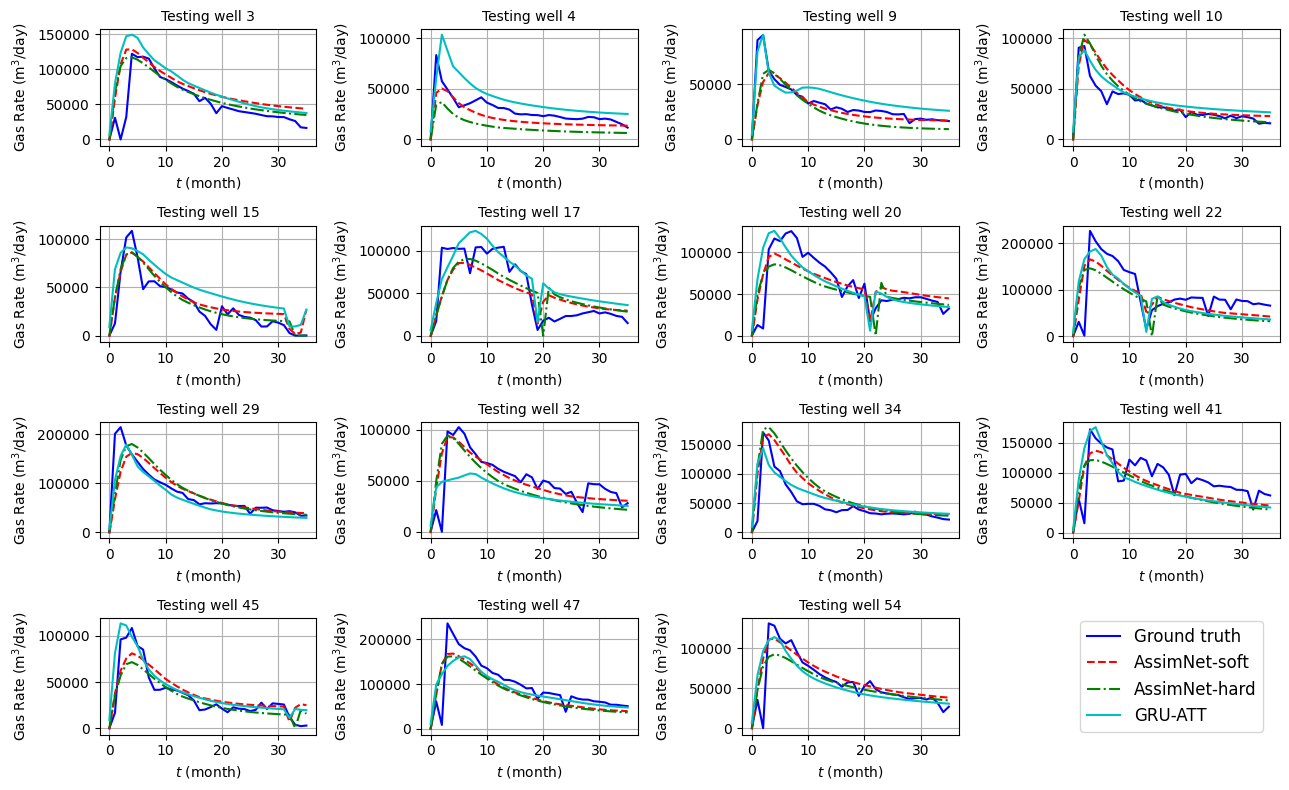

In [ ]:
from sklearn.metrics import mean_squared_error

gru_out = gru_model.predict([assim_x1_scaled_test, assim_x2_scaled_test])
gru_out_flat = gru_out.reshape(-1, 1)

# z_mean, z_log_var, z = AssimNet_encoder.predict([assim_x1_scaled])
hard_pred = pickle.load(open('processed data0/inference_gas_rate.pkl', 'rb'))
z_mean, z_log_var, z = AssimNet_encoder.predict([assim_x1_scaled_test])
simu_in_recons = decoder_model.predict([z])
simu_in_concate = assemble_simu_in(tf.cast(simu_in_recons, tf.float32),tf.cast(assim_x2_scaled_test, tf.float32))
proxy_out = proxy.predict(simu_in_concate)
proxy_out_flat = proxy_out.reshape(-1, 1)

# invserse
assim_y_org_scaled_flat = assim_y_org_scaled_test.reshape(-1, 1)
assim_y_scaled_flat = assim_y_scaled_test.reshape(-1, 1)
original_shape = gru_out.shape
assim_y_org_inversed = y_scaler.inverse_transform(assim_y_org_scaled_flat).reshape(original_shape)
assim_y_test_inversed = y_scaler.inverse_transform(assim_y_scaled_flat).reshape(original_shape)
proxy_out_inversed = y_scaler.inverse_transform(proxy_out_flat).reshape(original_shape)
gru_out_inversed = y_scaler.inverse_transform(gru_out_flat).reshape(original_shape)

rmse = np.sqrt(mean_squared_error(assim_y_org_inversed.reshape(-1),gru_out_inversed.reshape(-1)))
print(rmse)

fig, ax = plt.subplots(4, 4, figsize=(13, 8))
ax = ax.flatten()
n_plots = sorted(np.random.choice(59, size=15, replace=False))
nn = 0
for i in range(15):
    n_plot = n_plots[i]
    # ax[i].plot(assim_y_test_inversed[n_plot, :, 0], label='Denoised Gas Rate', color='orange')
    ax[i].plot(assim_y_org_inversed[n_plot, :, 0], label='Ground truth', color='blue')
    ax[i].plot(proxy_out_inversed[n_plot, :, 0], label='AssimNet-soft', linestyle='--', color='red')
    ax[i].plot(hard_pred[nn, :], linestyle='-.', label='AssimNet-hard', color='green')
    ax[i].plot(gru_out_inversed[n_plot, :, 0], linestyle='-', label='GRU-ATT', color='c')
    # if i == 0:
    #   ax[i].legend()

    ax[i].set_ylabel('Gas Rate (m$^3$/day)',fontsize=10)
    ax[i].set_xlabel('$t$ (month)',fontsize=10)
    ax[i].set_title(f'Testing well {n_plot+1}',fontsize=10)
    ax[i].grid(True)
    nn+=1

# 16th subplot: legend only
ax[15].axis('off')
# l1, = ax[15].plot([], [], color='orange', linestyle='-', label='Denoised Gas Rate')
l2, = ax[15].plot([], [], color='blue', linestyle='-', label='Ground truth')
l3, = ax[15].plot([], [], color='red', linestyle='--', label='AssimNet-soft')
l4, = ax[15].plot([], [], color='green', linestyle='-.', label='AssimNet-hard')
l5, = ax[15].plot([], [], color='c', linestyle='-', label='GRU-ATT')
ax[15].legend(handles=[l2, l3, l4, l5], loc='center', fontsize=12)

plt.tight_layout()
plt.show()